# Önem Haritaları İçin Sağlama Testleri
## 1. Araştırma amacı ve önceden belirlenen hipotezler

**Tania El Hawari — 20259258043**  
**Kaynak:** Julius Adebayo, Justin Gilmer, Michael Muelly, Ian Goodfellow, Moritz Hardt ve Been Kim, *Sanity Checks for Saliency Maps*, NeurIPS 2018, [arXiv v3](https://arxiv.org/html/1810.03292v3).

Seçenek 1 kapsamında, bir açıklamanın ikna edici görünümü ile öğrenilmiş parametrelere veya etiket ilişkisine duyarlılığı arasındaki fark incelendi. Deneyler açıklamalara yönelik kontrollü müdahaleler kullanır. Bir modelin sınıflandırma başarısı tek başına açıklamasını doğrulamaz.

- **H1:** Çıkıştan girişe doğru rastgeleleştirme, temel gradyanın işaretli sıra benzerliğini düşürür. Yalnızca bir katmanı yeniden başlatan kontrolde düşüşün katmana göre değişmesi beklenir.
- **H2:** Rastgele etiketleri ezberleyen modelin gerçek etiketlerle test doğruluğu şans düzeyine yaklaşır. Aynı örnek ve hedef sınıf için haritaların benzerliği yöntemlere göre farklılaşır. Ezberleme zayıf kalırsa bu müdahalenin yorumu sınırlıdır.
- **H3:** Özellikle girdi ile çarpılan yöntemlerde geometrik yapı görünür kalabilir. İşaretli ve mutlak sıra benzerlikleri farklı davranabilir. Bir kenar haritası modelden bağımsız görsel kontrol sağlar. Evrensel geçme eşiği kullanılmaz.

Uygulama ve rapor, yapay zekâ destekli kodlama yardımıyla hazırlandı. Defterin yürütülmesi ve rapor çıktılarının teknik karşılaştırması bu yardım kapsamında gerçekleştirildi.

## 2. Kullanılan Python Kütüphaneleri

| Kütüphane | Kullanım ve gerekçe |
|---|---|
| Python standart kütüphanesi | pathlib dosya yolları, copy model kopyaları, json defter okuma, re rapor biçimleme, hashlib görüntü bütünlüğü, html güvenli tablo biçimleme |
| NumPy | Tohumlu veri, piksel gürültüsü, vektör ve histogram işlemleri |
| pandas | Veri manifestosunu yazma ve okuma, ölçüm tabloları ve gruplama |
| Pillow | NumPy piksel dizilerini PNG olarak kaydetme, görüntüleri okuma, EXIF yönünü düzeltme, gri tona dönüştürme ve yeniden boyutlandırma |
| PyTorch | CNN katmanları, DataLoader, kayıp ve Adam, autograd ile hedef logit türevi |
| SciPy | Eşit değerlere ortalama sıra ve SSIM için Gauss filtreleme |
| Matplotlib | Deney figürleri ve PNG çıktıları |
| JupyterLab (isteğe bağlı), ipykernel ve matplotlib-inline | Etkileşimli çalıştırma ortamı |

Bunlar genel amaçlı araçlardır. Açıklama yöntemlerinin hesaplama adımları aşağıdaki hücrelerde tanımlanır.

In [1]:
from pathlib import Path
from copy import deepcopy
from hashlib import sha256
import html

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from scipy.stats import rankdata
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "analiz.ipynb").is_file(), "Defteri proje klasöründen çalıştırın."
DATA = ROOT / "data"
SEED = 7342
SIDE = 32
PHOTO_MODE = False
OUTPUT = ROOT / "foto-sonuclari" if PHOTO_MODE else ROOT
FIG = OUTPUT / "sekiller"
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
CLASSES = ("halka", "arti")
COUNTS = {"train": 256, "validation": 64, "test": 96}

def show_save(fig, filename):
    fig.savefig(FIG / filename, dpi=135, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("PyTorch", torch.__version__, "| CPU | tohum", SEED)

PyTorch 2.15.0+cpu | CPU | tohum 7342


## 3. Matematiksel temel

$x\in[0,1]^{32\times32}$ bir gri tonlu girdi, $\theta$ ağ parametreleri, $s_\theta(x)\in\mathbb{R}^2$ sınıf logitleridir. Hedef sınıf $c$ için açıklama aynı $s_c$ üzerinden hesaplanır. Kayıp $-\log(\exp(s_y)/\sum_j\exp(s_j))$ gerçek sınıf $y$ için normalize olasılığı büyütür. Eğitimde geri yayılım zincir kuralıyla kaybın parametre türevini, açıklamada ise logitin girdi türevini hesaplar.

$$G_c(x)=\nabla_x s_c(x),\qquad A_c(x)=x\odot G_c(x).$$

$G$ yerel birinci türevdir, $\odot$ piksel başına çarpımdır. Girdiyle çarpım, türev değişse bile benzer girdi bölgelerini öne çıkarabilir.

$$IG_c(x)=(x-x_0)\odot\int_0^1 \left.\nabla_z s_c(z)\right|_{z=x_0+t(x-x_0)}dt.$$

$x_0=0$ siyah referans, $t$ yol parametresidir. Türev yol noktasındaki model girdisine göredir. Trapez yaklaşımı kullanılır. SmoothGrad, $N^{-1}\sum_i G_c(x+\epsilon_i)$ ile gürültülü girdilerdeki türevleri ortalar. $\epsilon_i$ bağımsız Gauss gürültüsüdür ve karşılaştırmalarda aynı örnekler tekrar kullanılır.

Guided Backpropagation (GBP), ReLU geri geçişinde üstten gelen türevi $r\,\mathbf{1}_{r>0}\mathbf{1}_{a>0}$ ile kapılar. $a$ ileri geçişteki ReLU öncesi değerdir. Bu değiştirilmiş geri geçiş, modelin sıradan türevi değildir.

Grad-CAM için $A^k$ son evrişim öznitelik haritası, $Z$ uzamsal konum sayısıdır. $\alpha_k=Z^{-1}\sum_{ij}\partial s_c/\partial A^k_{ij}$, $L^c=\operatorname{ReLU}(\sum_k\alpha_k A^k)$ kullanılır. Harita bilineer büyütülür. Guided Grad-CAM, bu haritayı GBP ile çarpar. Düşük uzamsal çözünürlük, negatif kanıtın atılması, referans seçimi ve yerel doygunluk yöntemlerin yorum sınırlarıdır.

## 4. Veri üretimi ve hazırlık

Halka ve artı, sınıfı belirleyen gerçek şekillerdir. Köşedeki açık işaret eğitimde sınıfla %85 olasılıkla uyumlu seçilir. Doğrulama ve testte işaret, sınıftan bağımsız üretilir. Arka plan dalgaları, Gauss gürültüsü, yön, konum, ölçek ve şerit biçimli kısmi örtülme değişir. Sınıflar her bölmede eşit sayıdadır. Tohum ve görüntü karması veri kökenini izlemeyi sağlar.

Fotoğraf protokolü, değişen ışık, açı, arka plan ve örtülme koşullarında öğrencinin çektiği halka ve artı nesnelerini öngörür. Her fiziksel nesne ve ilişkili çekim oturumları tek bölmeye atanır. Manifesto biçimi ve PHOTO_MODE ayarı README’de açıklanır. Kaydedilmiş araştırma koşusu 416 sentetik görüntü kullanır. Öğretmenin gerçek dünya verisiyle canlı kod gerekliliği için kişisel fotoğraf koşusu ayrıdır. Fotoğraf modu CSV, grafik ve raporları foto-sonuclari/ altında üretir. Fotoğraflar EXIF yönüne göre düzeltilir, gri tona çevrilir ve nesneyi merkezden kesmemek için en-boy oranı korunarak 32×32 tuvale sığdırılır. Girdi paneli, nesnenin bu ölçekte ayırt edilebilirliğini incelemek için kullanılır.

label         0    1
split               
test         48   48
train       128  128
validation   32   32


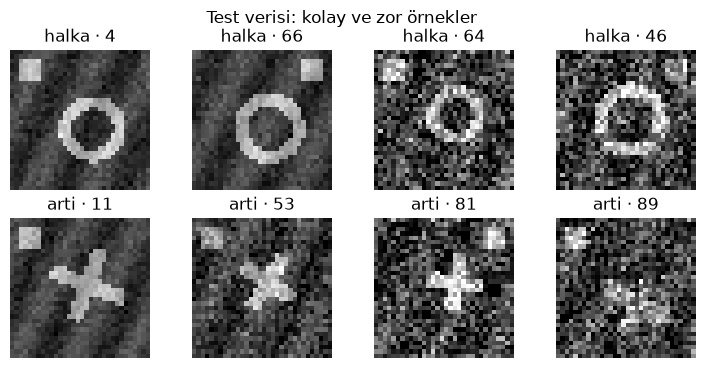

In [2]:
def synthetic_image(rng, label, cue, noise, occluded):
    center = rng.uniform(13, 19, size=2)
    radius = rng.uniform(6, 9)
    angle = rng.uniform(0, np.pi)
    yy, xx = np.mgrid[:SIDE, :SIDE]
    dx, dy = xx - center[0], yy - center[1]
    u = dx * np.cos(angle) + dy * np.sin(angle)
    v = -dx * np.sin(angle) + dy * np.cos(angle)
    distance = np.hypot(dx, dy)
    if label == 0:
        shape = (distance < radius) & (distance > radius * 0.62)
    else:
        shape = ((abs(u) < 1.7) & (abs(v) < radius)) | ((abs(v) < 1.7) & (abs(u) < radius))
    pixels = 0.23 + 0.10 * np.sin((xx + 0.5 * yy) / 2.1 + rng.uniform(0, 6))
    pixels += rng.normal(0, noise, pixels.shape)
    pixels += shape * rng.uniform(0.36, 0.62)
    col = 2 if cue == 0 else 25
    pixels[2:7, col:col + 5] += 0.46
    if occluded:
        row = rng.integers(12, 20)
        pixels[row:row + 2, 8:24] *= 0.43
    image = Image.fromarray(np.uint8(np.clip(pixels, 0, 1) * 255))
    return image, {"x": round(center[0], 3), "y": round(center[1], 3),
                   "radius": round(radius, 3), "angle_rad": round(angle, 3)}

def build_synthetic():
    rows = []
    seeds = np.random.SeedSequence(SEED).spawn(sum(COUNTS.values()))
    for split, count in COUNTS.items():
        directory = DATA / "synthetic" / split
        directory.mkdir(parents=True, exist_ok=True)
        for index in range(count):
            sample_seed = int(seeds[len(rows)].generate_state(1)[0])
            rng = np.random.default_rng(sample_seed)
            label = index % 2
            cue = (label if rng.random() < .85 else 1 - label) if split == "train" else int(rng.integers(2))
            noise = float(rng.choice([.05, .11, .19]))
            occluded = bool(rng.random() < .28)
            image, geometry = synthetic_image(rng, label, cue, noise, occluded)
            image_id = f"{split}-{index:04d}"
            path = directory / f"{image_id}.png"
            image.save(path)
            rows.append(dict(image_id=image_id, path=path.relative_to(ROOT).as_posix(),
                             label=label, class_name=CLASSES[label], split=split,
                             cue=cue, noise=noise, occluded=occluded, seed=sample_seed,
                             provenance="synthetic", group_id=image_id, **geometry))
    return pd.DataFrame(rows)

def photo_pixels(image):
    gray = ImageOps.exif_transpose(image).convert("L")
    return ImageOps.pad(gray, (SIDE, SIDE), method=Image.Resampling.LANCZOS, color=127)

def read_photo_manifest(root):
    raw = (root / "data" / "raw").resolve()
    csv_path = raw / "foto_manifest.csv"
    if not csv_path.is_file():
        raise ValueError("Fotoğraf manifestosu eksik: data/raw/foto_manifest.csv. README örneğini izleyin.")
    try:
        rows = pd.read_csv(csv_path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    except (OSError, UnicodeError, ValueError) as error:
        raise ValueError(f"Fotoğraf manifestosu okunamadı: {error}") from error
    required = ["image_id", "path", "label", "class_name", "split", "group_id"]
    missing = set(required) - set(rows.columns)
    if missing:
        raise ValueError("Manifestoda eksik sütunlar: " + ", ".join(sorted(missing)))
    for column in required:
        rows[column] = rows[column].str.strip()
    if rows.empty or rows[required].eq("").any().any():
        raise ValueError("Manifesto boş veya zorunlu alanlardan biri boş.")
    if not rows.image_id.is_unique:
        raise ValueError("image_id değerleri benzersiz olmalı.")
    if not rows.label.isin(["0", "1"]).all() or not rows.split.isin(COUNTS).all():
        raise ValueError("label 0 veya 1, split train, validation veya test olmalı.")
    rows["label"] = rows.label.astype(int)
    if not (rows.class_name == rows.label.map(dict(enumerate(CLASSES)))).all():
        raise ValueError("class_name ve label eşleşmeli: 0 = halka, 1 = arti.")
    if rows.groupby("group_id").split.nunique().gt(1).any():
        raise ValueError("Aynı nesne/çekim grubu birden fazla bölmede bulunuyor.")
    counts = pd.crosstab(rows.split, rows.label).reindex(index=COUNTS, columns=[0, 1], fill_value=0)
    if (counts < 8).any().any():
        raise ValueError(f"Her bölmede her sınıftan en az 8 fotoğraf gerekli. Mevcut sayılar:\n{counts}")
    resolved, hashes, model_hashes, widths, heights = set(), [], [], [], []
    for row in rows.itertuples(index=False):
        candidate = Path(row.path)
        file = (root / candidate).resolve()
        if candidate.is_absolute() or not file.is_relative_to(raw) or not file.is_file():
            raise ValueError(f"{row.image_id}: data/raw/ altında mevcut bir göreli dosya yolu gerekli: {row.path}")
        if file in resolved:
            raise ValueError(f"{row.image_id}: aynı görüntü yolu birden fazla kullanılmış: {row.path}")
        resolved.add(file)
        try:
            with Image.open(file) as image:
                if image.format not in {"JPEG", "PNG"} or min(image.size) < 64:
                    raise ValueError("Görüntü JPEG/PNG olmalı ve kısa kenarı en az 64 piksel olmalı.")
                image.load()
                widths.append(image.width)
                heights.append(image.height)
                model_hashes.append(sha256(photo_pixels(image).tobytes()).hexdigest())
            hashes.append(sha256(file.read_bytes()).hexdigest())
        except (OSError, ValueError, Image.DecompressionBombError) as error:
            raise ValueError(f"{row.image_id} ({row.path}): {error}") from error
    rows = rows.assign(sha256=hashes, model_sha256=model_hashes, width=widths, height=heights,
                       provenance="student_photo")
    for key in ("sha256", "model_sha256"):
        if rows.groupby(key).split.nunique().gt(1).any():
            raise ValueError("Aynı dosya veya aynı 32×32 girdi birden fazla bölmede bulunuyor.")
        if rows.groupby(key).label.nunique().gt(1).any():
            raise ValueError("Aynı görüntüye farklı sınıf etiketleri verilmiş.")
    return rows

if PHOTO_MODE:
    manifest = read_photo_manifest(ROOT)
else:
    manifest = build_synthetic()
    assert manifest.image_id.is_unique and manifest.path.is_unique
    assert set(manifest.split) == set(COUNTS) and set(manifest.label) == {0, 1}
    assert manifest.groupby("group_id").split.nunique().max() == 1
    manifest["sha256"] = [sha256((ROOT / path).read_bytes()).hexdigest() for path in manifest.path]
    assert manifest.groupby("sha256").split.nunique().max() == 1
FIG.mkdir(parents=True, exist_ok=True)
csv_output = OUTPUT / "veri.csv"
manifest.to_csv(csv_output, index=False, encoding="utf-8")
manifest = pd.read_csv(csv_output)
print(pd.crosstab(manifest.split, manifest.label).to_string())

def load_split(split):
    rows = manifest[manifest.split == split].reset_index(drop=True)
    images = []
    for path in rows.path:
        with Image.open(ROOT / path) as image:
            image = photo_pixels(image) if PHOTO_MODE else ImageOps.fit(image.convert("L"), (SIDE, SIDE))
            images.append(np.asarray(image, dtype=np.float32) / 255)
    return torch.from_numpy(np.stack(images))[:, None], torch.tensor(rows.label.to_numpy()), rows

train_x, train_y, train_rows = load_split("train")
valid_x, valid_y, _ = load_split("validation")
test_x, test_y, test_rows = load_split("test")
fig, axes = plt.subplots(2, 4, figsize=(9, 4))
for label, row_axes in enumerate(axes):
    examples = test_rows[test_rows.label == label]
    if not PHOTO_MODE:
        examples = examples.sort_values(["occluded", "noise"])
    for ax, i in zip(row_axes, np.linspace(0, len(examples) - 1, 4, dtype=int)):
        index = examples.index[i]
        ax.imshow(test_x[index, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{CLASSES[label]} · {index}")
        ax.axis("off")
fig.suptitle("Kişisel fotoğraf test örnekleri" if PHOTO_MODE else "Test verisi: kolay ve zor örnekler")
show_save(fig, "01-veri.png")

## 5. Evrişim ağı ve eğitim

32×32×1 → Conv(12, 3×3) → ReLU → 2×2 havuz → Conv(24, 3×3) → ReLU → 2×2 havuz → 1536 → Dense(96) → ReLU → Dense(2). Maksimum havuzlama yerel tepkileri korur. Tam bağlı katman konum bilgisini kullanabilir ve rastgele etiketleri ezberlemek için kapasite sağlar. Adam başlangıç adımı 0,002 ve mini yığın büyüklüğü 32’dir. Gerçek etiketli model, doğrulama kaybı en düşük olan dönemdeki ağırlıklarla değerlendirilir. Rastgele etiketli model, eğitim doğruluğu %97’ye eriştiğinde veya dönem bütçesi tükendiğinde durur. Test etiketleri model seçiminde kullanılmaz.

Test: loss=0.0229, accuracy=0.990
Karışıklık matrisi (gerçek × tahmin): [[48, 0], [1, 47]]


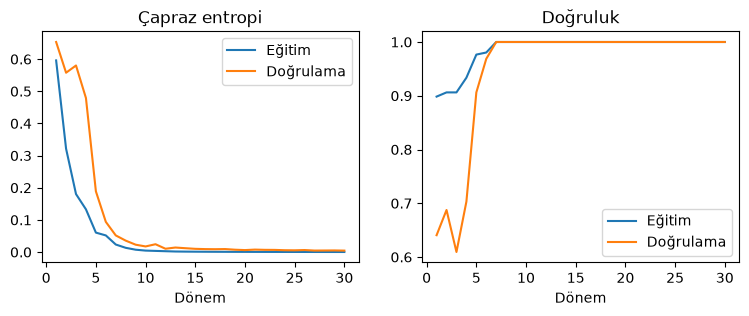

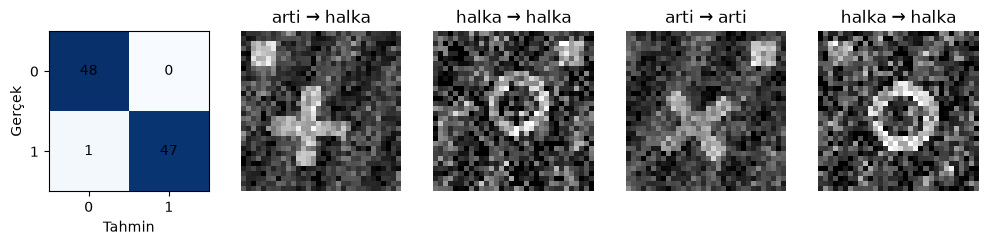

In [3]:
class GuidedReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x.clamp_min(0)

    @staticmethod
    def backward(ctx, incoming):
        x, = ctx.saved_tensors
        return incoming.clamp_min(0) * (x > 0)

class ShapeCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 12, 3, padding=1)
        self.conv2 = nn.Conv2d(12, 24, 3, padding=1)
        self.fc = nn.Linear(24 * 8 * 8, 96)
        self.head = nn.Linear(96, 2)

    def forward(self, x, guided=False, features=False):
        activate = GuidedReLU.apply if guided else F.relu
        x = F.max_pool2d(activate(self.conv1(x)), 2)
        a = activate(self.conv2(x))
        x = F.max_pool2d(a, 2).flatten(1)
        logits = self.head(activate(self.fc(x)))
        return (logits, a) if features else logits

def evaluate(model, x, y):
    model.eval()
    with torch.no_grad():
        logits = model(x)
        return float(F.cross_entropy(logits, y)), float((logits.argmax(1) == y).float().mean())

def fit(labels, epochs, randomized=False):
    torch.manual_seed(SEED)
    model = ShapeCNN()
    loader = DataLoader(TensorDataset(train_x, labels), batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED + 1))
    optimizer = torch.optim.Adam(model.parameters(), lr=.002)
    history, best_state, best_loss = [], None, float("inf")
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in loader:
            optimizer.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
        train_loss, train_acc = evaluate(model, train_x, labels)
        val_loss, val_acc = evaluate(model, valid_x, valid_y)
        history.append(dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                            val_loss=val_loss, val_acc=val_acc))
        if val_loss < best_loss:
            best_loss, best_state = val_loss, deepcopy(model.state_dict())
        if randomized and train_acc >= .97:
            break
    if not randomized:
        model.load_state_dict(best_state)
    return model.eval(), pd.DataFrame(history)

model, history = fit(train_y, 30)
baseline_state = deepcopy(model.state_dict())
base_loss, base_acc = evaluate(model, test_x, test_y)
with torch.no_grad():
    predictions = model(test_x).argmax(1)
confusion = torch.bincount(test_y * 2 + predictions, minlength=4).reshape(2, 2)
print(f"Test: loss={base_loss:.4f}, accuracy={base_acc:.3f}")
print("Karışıklık matrisi (gerçek × tahmin):", confusion.tolist())
if base_acc <= .60:
    print("Bu koşuda test doğruluğu %60 veya altında. Açıklama sonuçlarını öğrenilmiş ilişki kanıtı olarak yorumlamayın.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, key, title in zip(axes, ("loss", "acc"), ("Çapraz entropi", "Doğruluk")):
    for split, label in (("train", "Eğitim"), ("val", "Doğrulama")):
        ax.plot(history.epoch, history[f"{split}_{key}"], label=label)
    ax.set(xlabel="Dönem", title=title)
    ax.legend()
show_save(fig, "02-egitim.png")

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
axes[0].imshow(confusion, cmap="Blues")
axes[0].set(xlabel="Tahmin", ylabel="Gerçek", xticks=[0, 1], yticks=[0, 1])
for y in range(2):
    for x in range(2):
        axes[0].text(x, y, int(confusion[y, x]), ha="center", va="center")
wrong = torch.where(predictions != test_y)[0].tolist()
right = torch.where(predictions == test_y)[0].tolist()
examples = wrong[:2] + right[:4-len(wrong[:2])]
for ax, index in zip(axes[1:], examples):
    ax.imshow(test_x[index, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{CLASSES[test_y[index]]} → {CLASSES[predictions[index]]}")
    ax.axis("off")
show_save(fig, "03-hatalar.png")

## 6. Önem haritalarının uygulanması

Her modelde aynı gerçek sınıf logiti kullanılır. Bu seçim, modelin tahmini değiştiğinde farklı bir hedefi karşılaştırmayı önler. Autograd yalnızca türev hesaplar. Integrated Gradients için 32 trapez aralığı ve uçlar dâhil 33 değerlendirme noktası kullanılır. SmoothGrad, 16 gürültülü girdiyi ortalar. Gauss gürültüsünün ortalaması sıfır, standart sapması 0,08’dir. Değer, [0; 1] ölçeğindeki piksel girdisine eklenir. ReLU geri geçiş kuralı, yol integrali, gürültü ortalaması ve kanal ağırlıkları bu defterde uygulanır. SmoothGrad yerel gürültüyü azaltabilir, ancak gürültü ölçeğine bağlıdır. Grad-CAM ve Guided Grad-CAM için sıfır harita geçerli bir çıktıdır ve korelasyonu tanımsız olabilir.

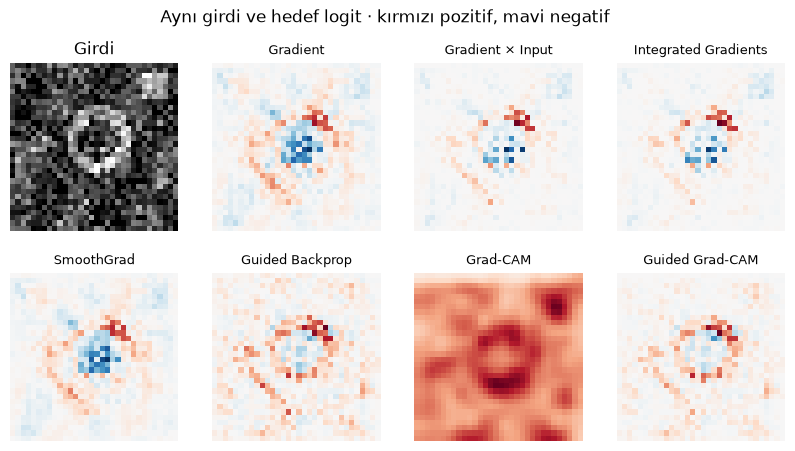

In [4]:
METHODS = ("Gradient", "Gradient × Input", "Integrated Gradients", "SmoothGrad",
           "Guided Backprop", "Grad-CAM", "Guided Grad-CAM")
STEPS = 32
NOISE_SAMPLES = 16

def gradient(model, batch, target, guided=False):
    x = batch.detach().requires_grad_(True)
    score = model(x, guided=guided)[:, target].sum()
    return torch.autograd.grad(score, x)[0].detach()

def explain(model, image, target, sample_index):
    x = image.unsqueeze(0)
    grad = gradient(model, x, target)
    guided = gradient(model, x, target, guided=True)
    t = torch.linspace(0, 1, STEPS + 1).view(-1, 1, 1, 1)
    path_grad = gradient(model, t * x, target)
    integrated = x * ((path_grad[:-1] + path_grad[1:]) / 2).mean(0, keepdim=True)
    rng = torch.Generator().manual_seed(SEED + 100 + sample_index)
    noise = .08 * torch.randn((NOISE_SAMPLES, *x.shape[1:]), generator=rng)
    smooth = gradient(model, x + noise, target).mean(0, keepdim=True)
    logits, features = model(x, features=True)
    weights = torch.autograd.grad(logits[0, target], features)[0].mean((-2, -1), keepdim=True)
    cam = (features * weights).sum(1, keepdim=True).relu()
    cam = F.interpolate(cam.detach(), size=(SIDE, SIDE), mode="bilinear", align_corners=False)
    maps = (grad, grad * x, integrated, smooth, guided, cam, cam * guided)
    flat = {method: value.squeeze().numpy() for method, value in zip(METHODS, maps)}
    assert all(value.shape == (SIDE, SIDE) and np.isfinite(value).all() for value in flat.values())
    return flat

# Deterministic, balanced evaluation panel chosen without examining maps or predictions.
panel = [int(i) for label in (0, 1) for i in np.flatnonzero(test_y.numpy() == label)[:8]]
def panel_maps(network):
    return {i: explain(network, test_x[i], int(test_y[i]), i) for i in panel}

original = panel_maps(model)
i = panel[0]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes.flat[0].imshow(test_x[i, 0], cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title("Girdi")
for ax, method in zip(axes.flat[1:], METHODS):
    a = original[i][method]
    scale = max(float(abs(a).max()), 1e-12)
    ax.imshow(a, cmap="RdBu_r", vmin=-scale, vmax=scale)
    ax.set_title(method, fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Aynı girdi ve hedef logit · kırmızı pozitif, mavi negatif")
show_save(fig, "04-yontemler.png")

## 7. Benzerlik ölçütleri ve kontroller

Spearman $\rho$ eşit değerlere ortalama sıra verildikten sonra iki sıra vektörünün Pearson korelasyonudur. İşaretli ve mutlak değerli haritalar ayrı değerlendirilir. Sabit bir vektör için korelasyon tanımsızdır. Böyle çiftler NaN olarak kaydedilir ve yalnızca tanımlı örnekler özetlenir. Rapor hem $n$ hem örnek standart sapmasını gösterir.

$$\operatorname{SSIM}(a,b)=\frac{(2\mu_a\mu_b+C_1)(2\sigma_{ab}+C_2)}
 {(\mu_a^2+\mu_b^2+C_1)(\sigma_a^2+\sigma_b^2+C_2)}.$$

Yerel momentler Gauss ağırlıklıdır. Her işaretli çift ortak mutlak maksimumla ölçeklenip [0; 1] aralığına taşınır. $C_1=(0{,}01)^2$ ve $C_2=(0{,}03)^2$ düşük varyans bölgelerinde bölümü kararlı kılar. Yerel değerlerin ortalaması raporlanır.

HOG, merkez fark gradyanlarının işaretsiz yönlerini dokuz kovaya toplar. Her 8×8 hücrede oylar gradyan büyüklüğüyle ağırlıklandırılır ve hücre histogramı L2 normuyla ölçeklenir. Birleştirilen betimleyicilerin Pearson korelasyonu yön yapısını ölçer. Bu basit HOG, makalenin blok normalizasyonlu kütüphane ayarının aynısı değildir.

In [5]:
def pearson(a, b):
    a = np.asarray(a, dtype=float).ravel()
    b = np.asarray(b, dtype=float).ravel()
    if np.ptp(a) == 0 or np.ptp(b) == 0:
        return np.nan
    a, b = a - a.mean(), b - b.mean()
    return float(np.clip(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))

def ssim(a, b):
    scale = max(float(abs(a).max()), float(abs(b).max()), 1e-12)
    a, b = .5 + .5 * a.astype(float) / scale, .5 + .5 * b.astype(float) / scale
    mean_a, mean_b = gaussian_filter(a, 1.5), gaussian_filter(b, 1.5)
    var_a = gaussian_filter(a * a, 1.5) - mean_a ** 2
    var_b = gaussian_filter(b * b, 1.5) - mean_b ** 2
    cov = gaussian_filter(a * b, 1.5) - mean_a * mean_b
    return float(np.mean((2 * mean_a * mean_b + .0001) * (2 * cov + .0009) /
                         ((mean_a ** 2 + mean_b ** 2 + .0001) * (var_a + var_b + .0009))))

def hog(a):
    gy, gx = np.gradient(a)
    amplitude = np.hypot(gx, gy)
    bins = ((np.arctan2(gy, gx) % np.pi) * (9 / np.pi)).astype(int).clip(0, 8)
    parts = []
    for row in range(0, SIDE, 8):
        for col in range(0, SIDE, 8):
            cell = np.s_[row:row + 8, col:col + 8]
            hist = np.bincount(bins[cell].ravel(), weights=amplitude[cell].ravel(), minlength=9)
            parts.append(hist / max(np.linalg.norm(hist), 1e-12))
    return np.concatenate(parts)

METRICS = ("Spearman", "Spearman_abs", "SSIM", "HOG")
def compare(a, b):
    return dict(zip(METRICS, (pearson(rankdata(a), rankdata(b)),
                             pearson(rankdata(abs(a)), rankdata(abs(b))),
                             ssim(a, b), pearson(hog(a), hog(b)))))

probe = np.arange(SIDE ** 2, dtype=float).reshape(SIDE, SIDE)
assert np.isclose(compare(probe, probe)["SSIM"], 1)
assert np.isclose(compare(probe, -probe)["Spearman"], -1)
assert np.isnan(compare(np.zeros_like(probe), probe)["Spearman"])
records = []

def record(experiment, stage, repeat, maps):
    for i in panel:
        for method in METHODS:
            records.append(dict(experiment=experiment, stage=stage, repeat=repeat,
                                image_id=test_rows.loc[i, "image_id"], target=int(test_y[i]),
                                method=method, **compare(original[i][method], maps[i][method])))

## 8. Deney 1 · Model parametrelerinin rastgeleleştirilmesi

Dört parametre bloğu çıkıştan girişe doğru head → fc → conv2 → conv1 sırasıyla değiştirilir. Her blok için PyTorch katmanının varsayılan başlangıç dağılımından yeni ağırlık ve bias çekilir. Bağımsız testte yalnızca ilgili blok değişir. Kademeli testte bu sıradaki önceki değişimler birikir. Aynı tekrardaki iki yaklaşım, her blok için aynı rastgele ağırlıkları kullanır. Üç tohum ve 16 test görüntüsü kullanılır. Standart sapma ve sayılar görüntü × tohum çiftlerinin betimleyici özetidir. Aynı görüntünün tekrarları bağımsız gözlem değildir.

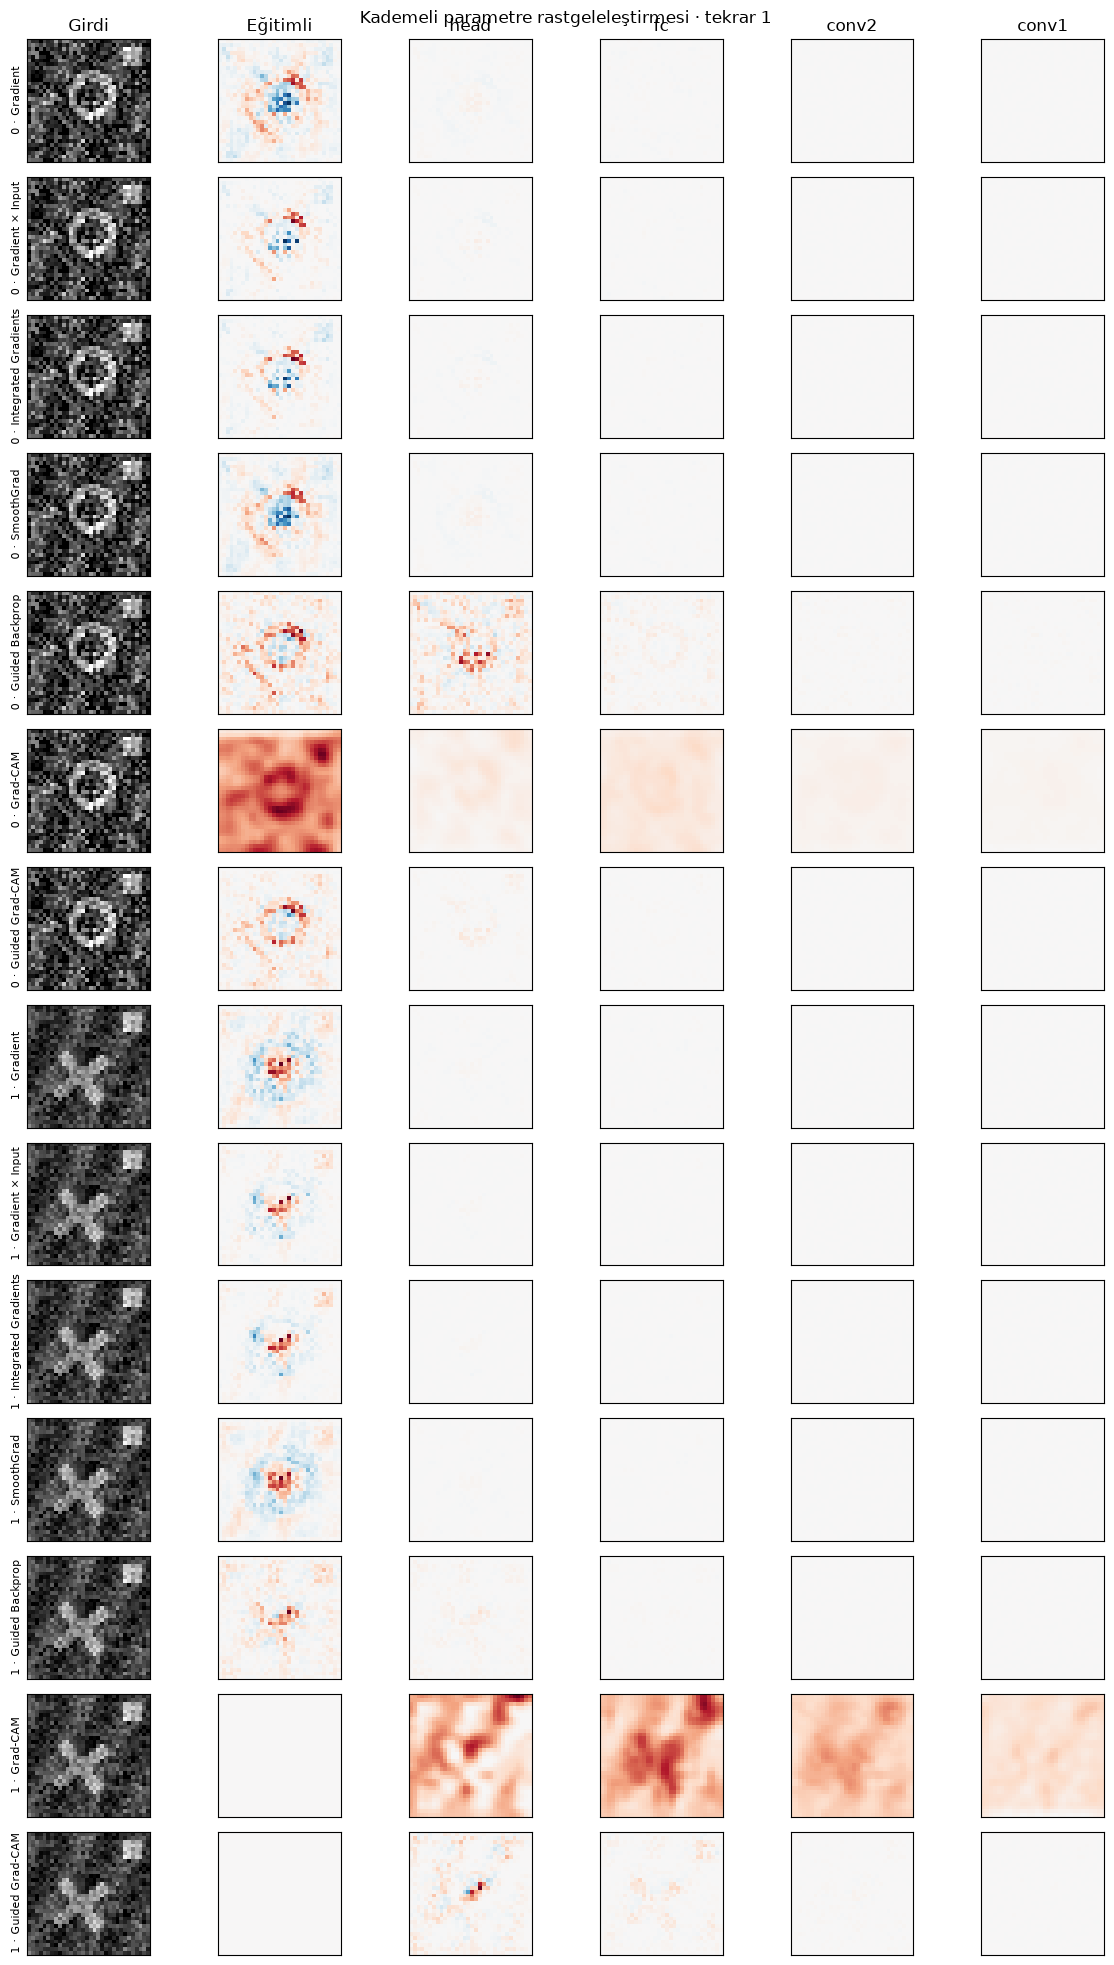

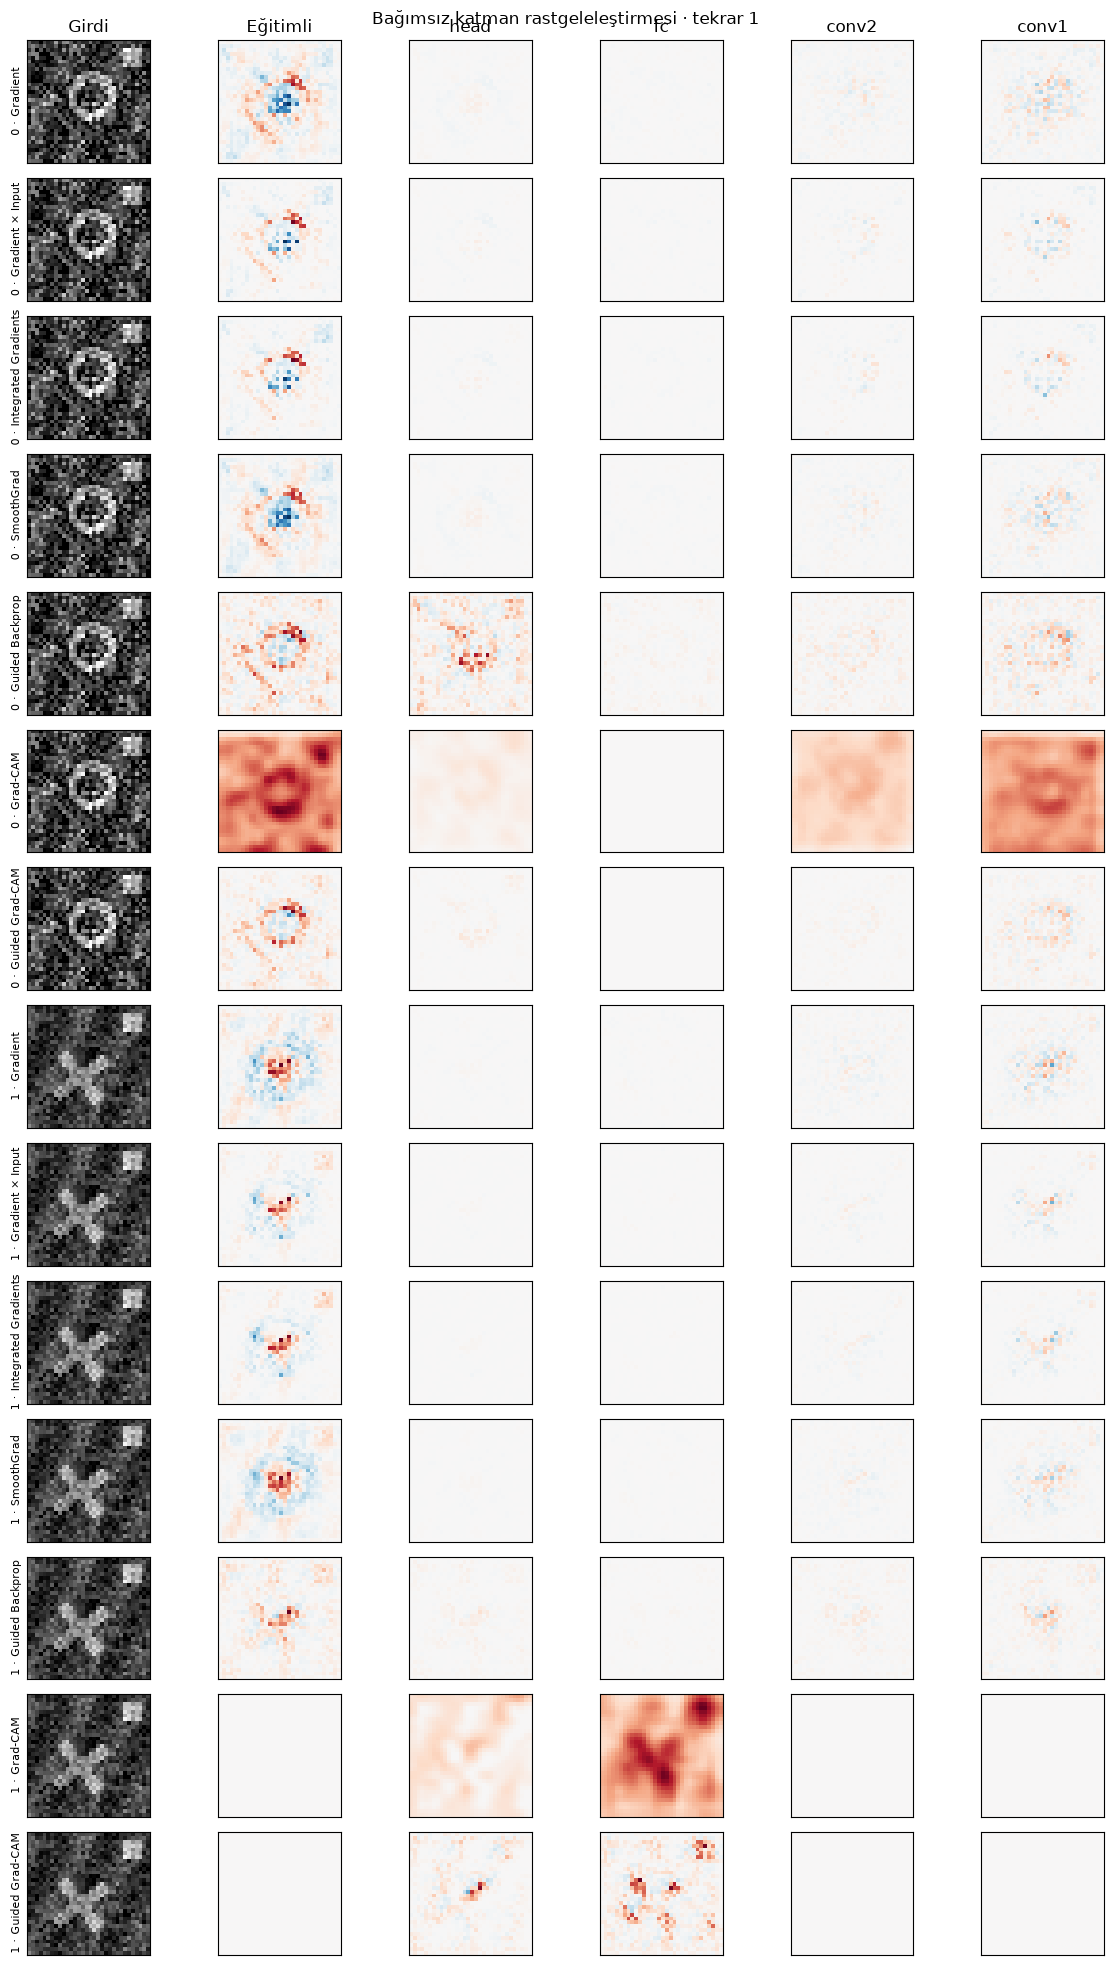

In [6]:
BLOCKS = ("head", "fc", "conv2", "conv1")
REPEATS = 3
first_cascade, first_independent = {}, {}
for repeat in range(REPEATS):
    cumulative = deepcopy(model)
    for offset, block in enumerate(BLOCKS):
        independent = deepcopy(model)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(SEED + 1000 + 100 * repeat + offset)
            getattr(independent, block).reset_parameters()
        getattr(cumulative, block).load_state_dict(getattr(independent, block).state_dict())
        current = panel_maps(cumulative)
        single = panel_maps(independent)
        record("Kademeli", block, repeat, current)
        record("Bağımsız", block, repeat, single)
        if repeat == 0:
            first_cascade[block] = current
            first_independent[block] = single

assert all(torch.equal(model.state_dict()[key], value) for key, value in baseline_state.items())

def show_stages(stages, title, filename):
    examples = (panel[0], panel[8])
    columns = ("Girdi", "Eğitimli", *stages)
    fig, axes = plt.subplots(2 * len(METHODS), len(columns), figsize=(12, 20))
    for row, (index, method) in enumerate((i, m) for i in examples for m in METHODS):
        x = test_x[index, 0]
        maps = [original[index][method], *(v[index][method] for v in stages.values())]
        limit = max(1e-12, *(float(abs(a).max()) for a in maps))
        axes[row, 0].imshow(x, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_ylabel(f"{index} · {method}", fontsize=8)
        for ax, a in zip(axes[row, 1:], maps):
            ax.imshow(a, cmap="RdBu_r", vmin=-limit, vmax=limit)
        for ax in axes[row]:
            ax.set(xticks=[], yticks=[])
    for ax, col in zip(axes[0], columns):
        ax.set_title(col)
    fig.suptitle(title)
    fig.tight_layout()
    show_save(fig, filename)

show_stages(first_cascade, "Kademeli parametre rastgeleleştirmesi · tekrar 1", "05-kademeli.png")
show_stages(first_independent, "Bağımsız katman rastgeleleştirmesi · tekrar 1", "06-bagimsiz.png")

## 9. Deney 2 · Eğitim etiketlerinin permütasyonu

Eğitim görüntüleri ve sınıf frekansları korunur. Sabit bir permütasyon eğitim etiketlerini görüntülerle yeniden eşler. Yeni ağ, temel ağ ile aynı başlangıç tohumunu ve mimariyi kullanır. Doğrulama ve test etiketleri korunur. Orijinal ve rastgele etiketli ağlar aynı test pikselleri ve aynı hedef logitle karşılaştırılır. Yüksek permüte eğitim doğruluğu, görüntülerle yapılan rastgele eşleştirmelerin ezberlenmesine ilişkin bir kontroldür.

Etiketi değişen örnek oranı: 0.484
Permüte eğitim doğruluğu 0.980; gerçek test doğruluğu 0.438


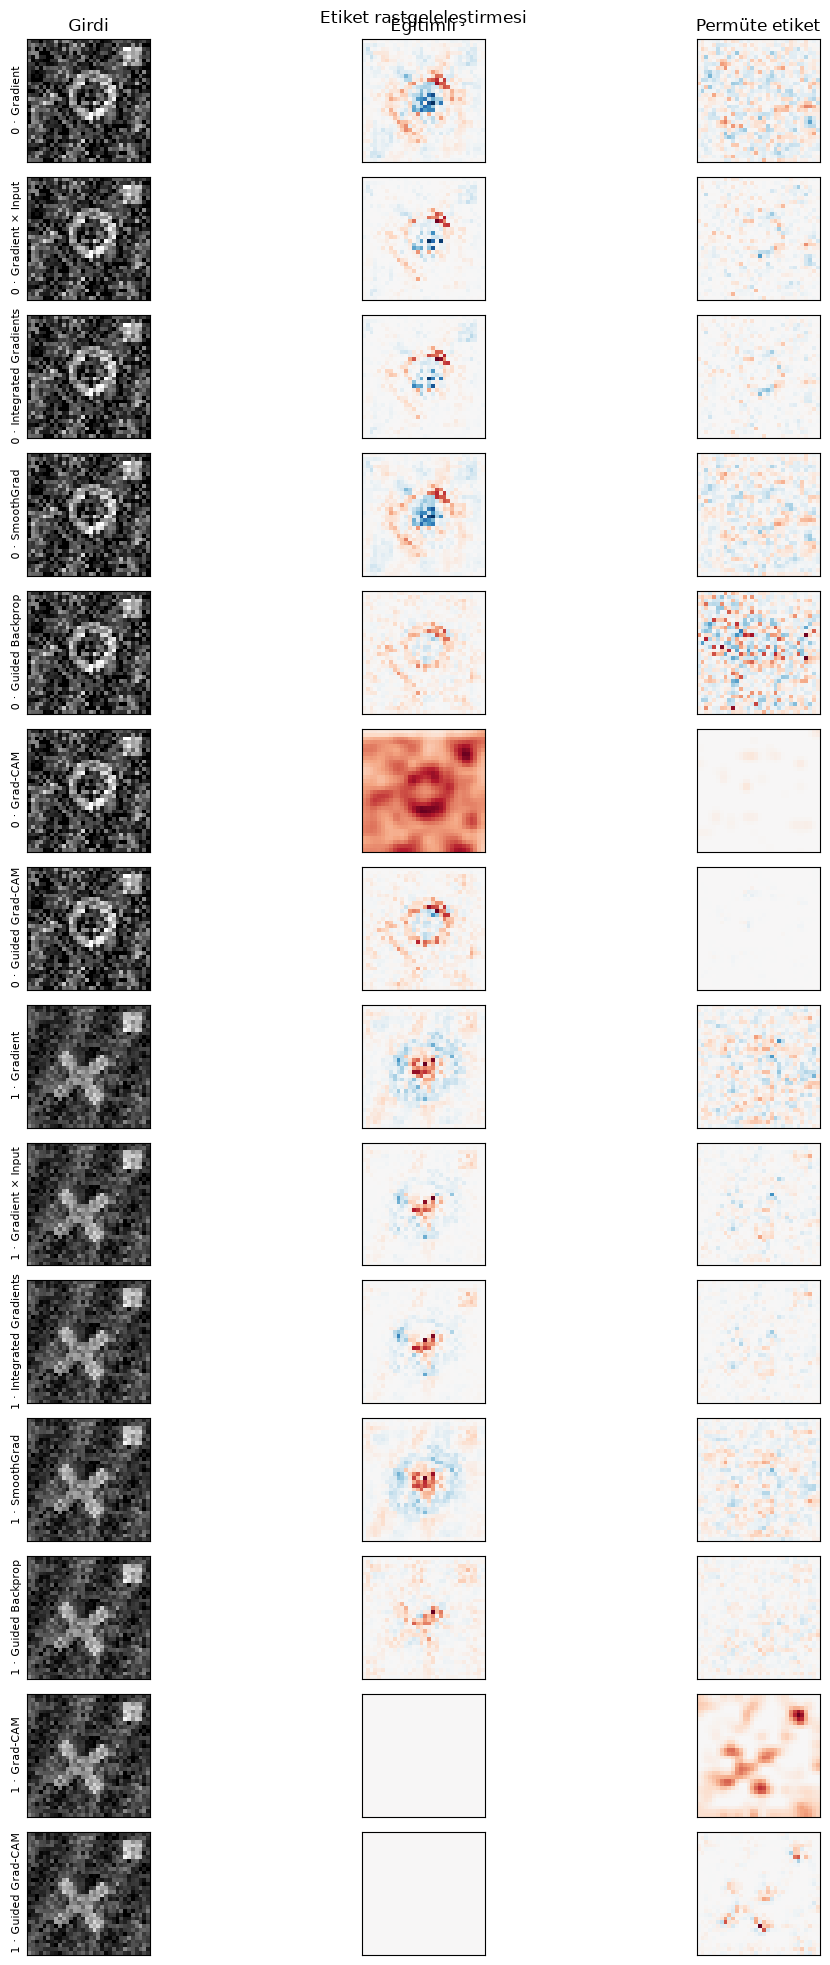

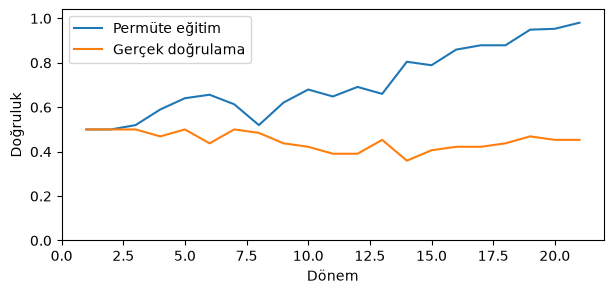

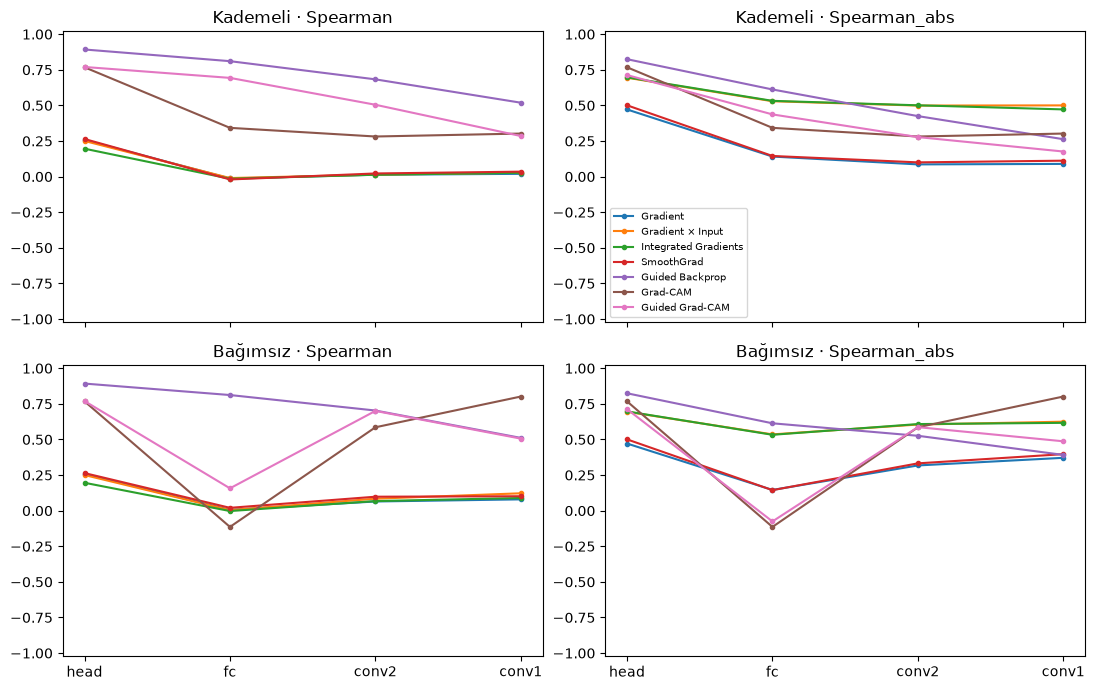

In [7]:
permutation = torch.randperm(len(train_y), generator=torch.Generator().manual_seed(SEED + 2000))
permuted = train_y[permutation]
assert torch.equal(train_y.bincount(), permuted.bincount())
random_model, random_history = fit(permuted, 110, randomized=True)
random_train_loss, random_train_acc = evaluate(random_model, train_x, permuted)
random_test_loss, random_test_acc = evaluate(random_model, test_x, test_y)
paired_maps = panel_maps(random_model)
record("Etiket", "Permütasyon", 0, paired_maps)
print(f"Etiketi değişen örnek oranı: {float((permuted != train_y).float().mean()):.3f}")
print(f"Permüte eğitim doğruluğu {random_train_acc:.3f}; gerçek test doğruluğu {random_test_acc:.3f}")
show_stages({"Permüte etiket": paired_maps}, "Etiket rastgeleleştirmesi", "07-etiket.png")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(random_history.epoch, random_history.train_acc, label="Permüte eğitim")
ax.plot(random_history.epoch, random_history.val_acc, label="Gerçek doğrulama")
ax.set(xlabel="Dönem", ylabel="Doğruluk", ylim=(0, 1.04))
ax.legend()
show_save(fig, "08-ezber.png")

scores = pd.DataFrame(records)
long = scores.melt(id_vars=["experiment", "stage", "repeat", "image_id", "target", "method"],
                   value_vars=METRICS, var_name="metric", value_name="value")
summary = long.groupby(["experiment", "stage", "method", "metric"], sort=False).value.agg(
    mean="mean", sd="std", n="count", total="size").reset_index()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for row, experiment in enumerate(("Kademeli", "Bağımsız")):
    for col, metric in enumerate(("Spearman", "Spearman_abs")):
        ax = axes[row, col]
        for method in METHODS:
            points = summary[(summary.experiment == experiment) & (summary.metric == metric) &
                             (summary.method == method)].set_index("stage").reindex(BLOCKS)
            ax.plot(BLOCKS, points["mean"], marker=".", label=method)
        ax.set(title=f"{experiment} · {metric}", ylim=(-1.02, 1.02))
axes[0, 1].legend(fontsize=7, loc="lower left")
fig.tight_layout()
show_save(fig, "09-benzerlik.png")

## 10. Seçenek 1: Zafiyet ve Manipülasyon Analizi

Rastgele ağırlıklı ağda aynı şekil veya kenarların görünmesi, tek başına ağın doğru sınıf ilişkisini öğrendiği anlamına gelmez. Aşağıdaki kontrol, ağ kullanmadan yalnızca görüntüdeki değişim büyüklüğünü gösterir. Aynı örnekte eğitimli ve tüm blokları sıfırdan başlatılmış ağların haritaları yer alır. İlk iki sıra işaretli ve mutlak atıfları yöntem başına ortak ölçekle gösterir. Üçüncü sıra her haritayı kendi maksimumuna böler. Bu sıra, genlik farkını saklayabilen harita başına normalizasyonu gözle görünür kılar. Kenar haritası görsel bir kıyas noktasıdır. Onun görünüşü bir insan değerlendirmesi veya nedensel doğruluk ölçümü değildir.

Parametre müdahalesi model bağımlılığını, etiket permütasyonu eğitimdeki örnek–etiket ilişkisine bağımlılığı yoklar. Bir yöntemin büyük değişim göstermesi onun kesinlikle doğru olduğunu kanıtlamaz. Düşük işaretli benzerlik ve aynı anda daha yüksek mutlak benzerlik gözlenirse, işareti atmanın bir müdahaleyi gizleyebildiği anlaşılır. Bu ayrışma görülmezse sonuç olduğu gibi raporlanır.

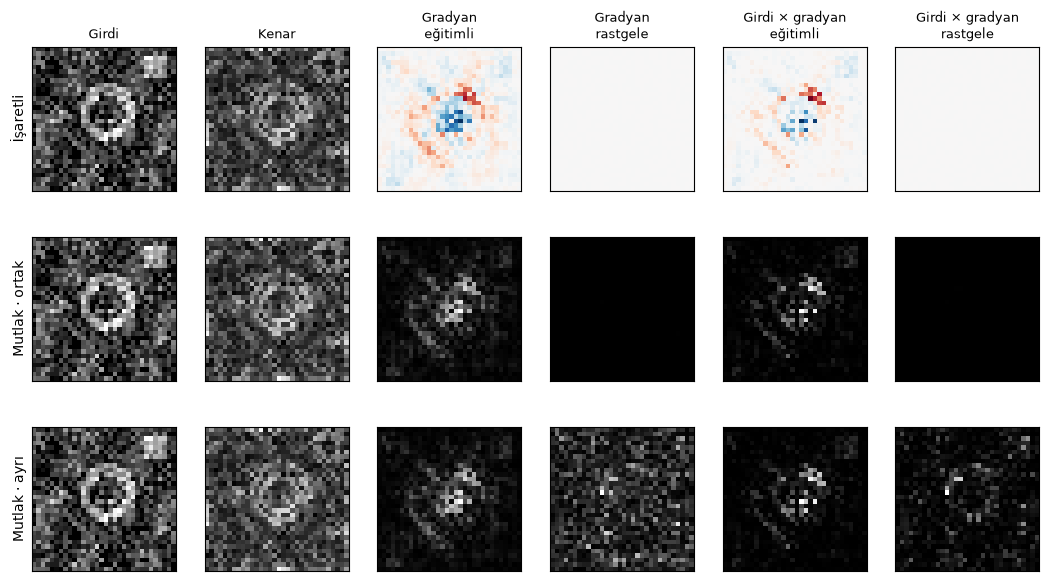

         Model  Eğitim doğruluğu  Test doğruluğu  Eğitim kaybı  Test kaybı  Eğitim dönemi
 Gerçek etiket            1.0000          0.9896        0.0003      0.0229             30
Permüte etiket            0.9805          0.4375        0.1696      1.4303             21
experiment       stage               method       metric      mean       sd  n  total
  Kademeli       conv1             Gradient     Spearman  0.019401 0.027442 48     48
  Kademeli       conv1     Gradient × Input     Spearman  0.027105 0.030273 48     48
  Kademeli       conv1 Integrated Gradients     Spearman  0.026625 0.039628 48     48
  Kademeli       conv1           SmoothGrad     Spearman  0.034731 0.040296 48     48
  Kademeli       conv1      Guided Backprop     Spearman  0.518932 0.044017 48     48
  Kademeli       conv1             Grad-CAM     Spearman  0.302202 0.422971 21     48
  Kademeli       conv1      Guided Grad-CAM     Spearman  0.284961 0.228035 21     48
    Etiket Permütasyon             Gradien

In [8]:
index = panel[0]
pixel_image = test_x[index, 0].numpy()
edge = np.hypot(*np.gradient(pixel_image))
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for row in range(3):
    absolute = row > 0
    axes[row, 0].imshow(pixel_image, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].imshow(edge, cmap="gray")
    for k, method in enumerate(("Gradient", "Gradient × Input")):
        a, b = original[index][method], first_cascade["conv1"][index][method]
        limit = max(float(abs(a).max()), float(abs(b).max()), 1e-12)
        for offset, value in enumerate((a, b)):
            scale = max(float(abs(value).max()), 1e-12) if row == 2 else limit
            axes[row, 2 + 2 * k + offset].imshow(abs(value) if absolute else value,
                cmap="gray" if absolute else "RdBu_r", vmin=0 if absolute else -scale, vmax=scale)
for ax, title in zip(axes[0], ("Girdi", "Kenar", "Gradyan\neğitimli", "Gradyan\nrastgele",
                               "Girdi × gradyan\neğitimli", "Girdi × gradyan\nrastgele")):
    ax.set_title(title, fontsize=9)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
axes[0, 0].set_ylabel("İşaretli")
axes[1, 0].set_ylabel("Mutlak · ortak")
axes[2, 0].set_ylabel("Mutlak · ayrı")
show_save(fig, "10-zafiyet.png")

# Add the two actual held-out models' performance and summarize measured effects.
base_train_loss, base_train_acc = evaluate(model, train_x, train_y)
perf = pd.DataFrame([
    ["Gerçek etiket", base_train_acc, base_acc, base_train_loss, base_loss, len(history)],
    ["Permüte etiket", random_train_acc, random_test_acc, random_train_loss, random_test_loss, len(random_history)]
], columns=["Model", "Eğitim doğruluğu", "Test doğruluğu", "Eğitim kaybı", "Test kaybı", "Eğitim dönemi"])
print(perf.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

chosen = summary[((summary.experiment == "Kademeli") & (summary.stage == "conv1")) |
                 (summary.experiment == "Etiket")]
print(chosen[chosen.metric.isin(["Spearman", "Spearman_abs"])].to_string(index=False))

def mean_score(experiment, stage, method, metric):
    row = summary[(summary.experiment == experiment) & (summary.stage == stage) &
                  (summary.method == method) & (summary.metric == metric)]
    return float(row["mean"].iloc[0])

g = mean_score("Kademeli", "conv1", "Gradient", "Spearman")
a = mean_score("Kademeli", "conv1", "Gradient × Input", "Spearman_abs")
signed = mean_score("Kademeli", "conv1", "Gradient × Input", "Spearman")
gap = a - signed
print(f"Tüm bloklar: Gradient işaretli {g:.3f}, Gradient × Input işaretli {signed:.3f}, mutlak {a:.3f}.")

## 11. Makaleyle karşılaştırma, geçerlilik ve canlı savunma

Adebayo ve arkadaşları gradyanın ve belirli katman koşullarında Grad-CAM’in duyarlı olduğunu, GBP ve Guided Grad-CAM’in üst katman değişimlerine görece duyarsız kalabildiğini, girdiyle çarpım içeren yöntemlerde görsel benzerliğin yanıltabileceğini bildirir. Makalenin v3 sürümü, GBP’nin tüm katmanlar için değişmez olduğu iddiasını düzeltir. Biz, sentetik veride tek CNN ve aynı hedef logit ile bu metodolojiyi sınadık. Inception, ImageNet, MNIST, Fashion-MNIST, radyografi, VarGrad ve makaledeki kuramsal evrişim deneyi kapsam dışıdır. Buradaki kenar kıyası, makalenin teori deneyinin yerine geçmez.

Rastgele etiket kontrolü tek permütasyondur. Parametre tohumları aynı 16 görüntüyü tekrar kullandığından satırlar bağımsız değildir. Testte köşe ipucunun ilişkisinin kaldırılması bir dağılım değişimidir. Gauss gürültüsü ve yapay şekiller fotoğraflara aktarım kanıtı sağlamaz. Mutlak değer, işareti siler. SSIM ve HOG mekânsal örüntüyü karşılaştırır ve nedensel açıklama doğruluğunu ölçmez. Düşük çözünürlüklü CAM ile piksel türevlerinin benzerlikleri aynı şekilde yorumlanmamalıdır.

### Canlı gösterim ve mevcut durum

Bu defterin kuramsal bölümleri canlı anlatımda matematiksel tanımlar ve yöntem sınırları için kullanılabilir. Sentetik Seçenek 1 koşusunda eğitim, iki parametre rastgeleleştirme düzeni ve etiket permütasyonu tamamlanmıştır. Gerçek dünya canlı kod aşaması kişisel fotoğrafların toplanmasına, manifesto doğrulamasına ve ayrı fotoğraf koşusunun değerlendirilmesine bağlıdır. Yükleyici her sınıf ve bölme için en az sekiz görüntü gerektirir. Toplam 48 görüntü, yazılımın kabul ettiği alt sınırdır. Öğretmenin fotoğraf sayısına ilişkin özgün yönergesi bu çalışma kapsamında doğrulanmamıştır. Kaydedilmiş sentetik bulgular fotoğraf koşusuna ait değildir.

Kısa sunumda 5. bölümün test başarısı, 8. bölümün çıkış ve tam model müdahaleleri ve 10. bölümün işaretli ve mutlak panelleri incelenebilir. Aynı hedef logitin kullanılması hedef değişimini model değişiminden ayırır. Test etiketlerinin korunması genellemenin gerçek hedefe göre ölçülmesini sağlar. Sıfır haritada sıra korelasyonu tanımsız olabilir. Bu durumda geçerli çift sayısı raporlanır. Autograd türevi hesaplar; bu defter hedefi, kapıyı, yol integralini, ortalamayı ve kanal ağırlıklarını tanımlar. VS Code’da çekirdek seçimi, çalışma sırası ve fotoğraf hazırlığı README’de belgelenmiştir.

In [9]:
import json
import re

def decimal_tr(value, digits, signed=False):
    sign = "+" if signed else ""
    return format(value, f"{sign}.{digits}f").replace(".", ",")

table_columns = {
    "experiment": "Deney", "stage": "Aşama", "method": "Yöntem", "metric": "Ölçüt",
    "mean": "Ortalama", "sd": "Örnek standart sapması", "n": "Tanımlı çift",
    "total": "Toplam çift",
}

g_head = mean_score("Kademeli", "head", "Guided Backprop", "Spearman")
g_all = mean_score("Kademeli", "conv1", "Guided Backprop", "Spearman")
gradient_head = mean_score("Kademeli", "head", "Gradient", "Spearman")
cam_head = mean_score("Kademeli", "head", "Grad-CAM", "Spearman")
perm_gradient = mean_score("Etiket", "Permütasyon", "Gradient", "Spearman")
data_label = "kişisel fotoğraf" if PHOTO_MODE else "sentetik"
memorization = ("Makaledeki %95 ölçütünü aştı." if random_train_acc > .95 else
                "Makaledeki %95 ölçütünü aşmadı. Düşük ezberleme bu karşılaştırmayı sınırlar.")

nb = json.loads((ROOT / "analiz.ipynb").read_text(encoding="utf-8"))
theory = ["".join(cell["source"]) for cell in nb["cells"] if cell["cell_type"] == "markdown"]
sections = [theory[0], theory[1], theory[2], theory[3], theory[4], theory[5], theory[6]]
sections += [
    f"""## Veri ve temel model sonuçları

Veri türü **{data_label}**. Eğitimde **{len(train_x)}**, doğrulamada **{len(valid_x)}**, testte **{len(test_x)}** görüntü kullanıldı. PyTorch {torch.__version__}, işlemci yürütmesi, tohum {SEED}.

{perf.to_html(index=False, float_format=lambda x: decimal_tr(x, 4), border=0)}

Temel modelin test karışıklık matrisi (gerçek × tahmin): {confusion.tolist()}. Doğrulama kaybı model kontrol noktası seçiminde kullanıldı. Test verisi ağırlık güncellemesinde kullanılmadı.

![Veri örnekleri](sekiller/01-veri.png)

![Eğitim ve doğrulama eğrileri](sekiller/02-egitim.png)

![Karışıklık matrisi ve örnek tahminler](sekiller/03-hatalar.png)

![Yedi önem haritası yöntemi](sekiller/04-yontemler.png)""",
    theory[7],
    """![Kademeli rastgeleleştirme](sekiller/05-kademeli.png)

![Bağımsız katman rastgeleleştirmesi](sekiller/06-bagimsiz.png)

![Katmanlara göre işaretli ve mutlak Spearman](sekiller/09-benzerlik.png)""",
    theory[8],
    f"""Permütasyon sonucu eğitim etiketlerinin %{decimal_tr(100 * float((permuted != train_y).float().mean()), 1)} kadarı değişti. Gerçek test etiketlerine göre doğruluk %{decimal_tr(100 * random_test_acc, 2)}, permüte eğitim etiketlerine göre doğruluk %{decimal_tr(100 * random_train_acc, 2)}. {memorization}

![Etiket rastgeleleştirme karşılaştırması](sekiller/07-etiket.png)

![Permütasyon eğitimi](sekiller/08-ezber.png)""",
    theory[9],
    f"""### Ölçülen zafiyet ve sonuç

Tüm parametre blokları yeniden başlatıldığında Gradient için ortalama işaretli Spearman **{decimal_tr(g, 3)}** oldu. Gradient × Input için işaretli ortalama **{decimal_tr(signed, 3)}**, mutlak ortalama **{decimal_tr(a, 3)}** ve fark **{decimal_tr(gap, 3, signed=True)}** oldu. {"Bu koşuda mutlak görselleştirme daha yüksek sıra benzerliği taşıdı." if gap > 0 else "Bu koşuda mutlak sıralama ortalaması işaretli değeri aşmadı."} Ortak ölçek genlik farkını korur. Her haritayı kendi içindeki maksimuma göre gösteren son sıra, zayıf sinyali büyütüp görsel yapının daha belirgin görünmesine yol açabilir. Girdi ve kenar panelleri modelden bağımsız kıyas sağlar. Tek bir görüntünün görünümü bütün yöntemler hakkında hüküm vermek için yeterli değildir.

Kademeli ilk adımda Gradient **{decimal_tr(gradient_head, 3)}**, Grad-CAM **{decimal_tr(cam_head, 3)}**, Guided Backprop **{decimal_tr(g_head, 3)}** işaretli sıra benzerliği verdi. Guided Backprop tüm katmanlar değiştiğinde **{decimal_tr(g_all, 3)}** oldu. Bu değerler üst ve alt katman davranışının aynı olup olmadığını bu ağ için gösterir ve makaledeki tüm mimarilere genellenemez. Permütasyon kontrolünde Gradient ortalaması **{decimal_tr(perm_gradient, 3)}** oldu. Tanımsız ölçümlerin sayısı toplam çift ile tanımlı çift sayısı arasındaki farktan okunabilir.

![Seçenek 1 görsel kontrolü](sekiller/10-zafiyet.png)

### Tüm benzerlik ölçümleri

Standart sapma yalnızca tanımlı çiftlerden hesaplanır. Bir standart sapma için en az iki tanımlı çift gerekir.

{summary.rename(columns=table_columns).to_html(index=False, float_format=lambda x: decimal_tr(x, 3), border=0, na_rep="Tanımsız")}""",
    theory[10].replace("Biz, sentetik veride tek CNN", "Biz, kişisel fotoğraflarda tek CNN")
              .replace("Testte köşe ipucunun ilişkisinin kaldırılması bir dağılım değişimidir. Gauss gürültüsü ve yapay şekiller fotoğraflara aktarım kanıtı sağlamaz.",
                       "Fotoğraf örneklemi iki nesne biçimiyle sınırlıdır. Sentetik koşudaki köşe ipucu bu fotoğraflara uygulanmadı.")
              if PHOTO_MODE else theory[10],
    f"""## 12. Sonuç

- **H1:** İlk blok müdahalesinden sonra Gradient sıra benzerliği {decimal_tr(gradient_head, 3)}, tüm bloklar değiştiğinde {decimal_tr(g, 3)}. Bağımsız blok testi, hangi müdahalelerin bu ağda daha fazla değişim ürettiğini ayrı ayrı gösterir.
- **H2:** Permüte eğitim ve gerçek test doğrulukları arasında {decimal_tr(100 * (random_train_acc - random_test_acc), 2)} puan fark ölçüldü. {memorization} Bu sonucu permütasyonun farklı tohumlarına genellemek için ek koşular gerekir.
- **H3:** Tam rastgeleleştirmeden sonra Gradient × Input için mutlak ve işaretli sıra benzerliği arasındaki fark {decimal_tr(gap, 3, signed=True)}. İşaret ve genlik bilgisi, bir haritanın tek başına görünüşünden çıkarılamaz.

Seçenek 1 açısından bu müdahaleler, model hata ayıklarken görsel benzerliğin bir doğrulama ölçütü olarak tek başına yeterli olmadığını gösterir. Her sonuç bu veri, ağ ve tohumlarla sınırlıdır.

**Kaynak.** Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M. ve Kim, B. (2018). *Sanity Checks for Saliency Maps*. NeurIPS 31. [arXiv v3](https://arxiv.org/html/1810.03292v3).""",
]
report = "\n\n".join(sections) + "\n"
(OUTPUT / "makale.md").write_text(report, encoding="utf-8")

# Small deterministic renderer for the Markdown constructs emitted above.
# Tables generated by pandas are retained as HTML blocks.
def inline_markup(value):
    value = html.escape(value)
    value = re.sub(r"\*\*(.+?)\*\*", r"<strong>\1</strong>", value)
    value = re.sub(r"(?<!\*)\*([^*\n]+)\*", r"<em>\1</em>", value)
    value = re.sub(r"\[([^\]]+)\]\((https://[^ )]+)\)", r'<a href="\2">\1</a>', value)
    return value.replace("  \n", "<br>\n")

def markdown_body(source):
    blocks = re.split(r"\n\s*\n|\n(?=#{1,3} )", source.strip())
    for block in blocks:
        if block.startswith("<table") and block.rstrip().endswith("</table>"):
            yield '<div class="table-wrap">' + block + "</div>"
            continue
        if block.startswith("$$"):
            yield '<p class="math">' + html.escape(block) + "</p>"
            continue
        if all(line.startswith("|") for line in block.splitlines()):
            rows = [[item.strip() for item in line.strip("|").split("|")]
                    for line in block.splitlines()]
            head = "".join(f"<th>{inline_markup(item)}</th>" for item in rows[0])
            body = "".join("<tr>" + "".join(f"<td>{inline_markup(item)}</td>" for item in row) +
                           "</tr>" for row in rows[2:])
            yield f'<div class="table-wrap"><table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'
            continue
        if block.startswith("- "):
            yield "<ul>" + "".join(f"<li>{inline_markup(line[2:])}</li>" for line in block.splitlines()) + "</ul>"
            continue
        image = re.fullmatch(r"!\[([^\]]+)\]\((sekiller/[^ )]+)\)", block)
        if image:
            caption, path = map(html.escape, image.groups())
            yield f'<figure><img src="{path}" alt="{caption}"><figcaption>{caption}</figcaption></figure>'
            continue
        heading = re.match(r"^(#{1,3}) (.+?)(?:\n(.*))?$", block, re.S)
        if heading:
            level, title, remainder = len(heading[1]), heading[2], heading[3]
            yield f"<h{level}>{inline_markup(title)}</h{level}>"
            if not remainder:
                continue
            block = remainder
        yield f"<p>{inline_markup(block)}</p>"

page = """<!doctype html>
<html lang="tr"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Önem Haritaları İçin Sağlama Testleri</title>
<script>window.MathJax={tex:{inlineMath:[['$','$']],displayMath:[['$$','$$']]}};</script>
<script defer src="https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-chtml.js"></script>
<style>
body{margin:0;background:#f4f6f9;color:#172635;font:17px/1.65 system-ui,sans-serif}
main{max-width:70rem;margin:auto;padding:2rem clamp(1rem,4vw,3rem);background:white}
h1,h2,h3{line-height:1.25;color:#142b45} h2{margin-top:2.2rem}
a{color:#145780} img{display:block;max-width:100%;height:auto;margin:auto}
figure{margin:1.5rem 0} figcaption{font-size:.9rem;text-align:center;color:#405466}
.table-wrap{overflow:auto} table{border-collapse:collapse;width:100%;font-size:.88rem}
th,td{padding:.35rem .55rem;border-bottom:1px solid #dfe7ee;text-align:left}
th{background:#e8eff6} .math{overflow:auto}
</style></head><body><main>"""
source = (OUTPUT / "makale.md").read_text(encoding="utf-8")
(OUTPUT / "makale.html").write_text(page + "\n".join(markdown_body(source)) +
                                 "</main></body></html>\n", encoding="utf-8")
print(f"{OUTPUT}: makale.md ve makale.html, ölçülen sonuçlardan üretildi.")

C:\Users\Admin\Desktop\xai_makale_2026\2026_guz\02_interpretability\makale-yeniden-uretim: makale.md ve makale.html, ölçülen sonuçlardan üretildi.
